In [16]:
import numpy as np
import pandas as pd
import xarray as xr
import torch
import matplotlib.pyplot as plt

# import region bounds
from regions import ROSS_ISLAND_BOUNDS

# assign region bounds
x_min = ROSS_ISLAND_BOUNDS["x_min"]
x_max = ROSS_ISLAND_BOUNDS["x_max"]
y_min = ROSS_ISLAND_BOUNDS["y_min"]
y_max = ROSS_ISLAND_BOUNDS["y_max"]

# Load MEaSUREs Phase-Based Antarctica Ice Velocity Map

We use [MEaSUREs Phase-Based Antarctica Ice Velocity Map, Version 1](https://nsidc.org/data/nsidc-0754/versions/1)

Reference:
- *Mouginot, J., Rignot, E. & Scheuchl, B. (2019). MEaSUREs Phase-Based Antarctica Ice Velocity Map. (NSIDC-0754, Version 1). [Data Set]. Boulder, Colorado USA. NASA National Snow and Ice Data Center Distributed Active Archive Center. https://doi.org/10.5067/PZ3NJ5RXRH10. Date Accessed 10-02-2025.*

In [5]:
# TODO define local path or full path to ice velocity data
ice_vel_phase = xr.load_dataset("/home/kim/data/nsidc/antarctic_ice_vel_phase_map_v01.nc")

# Define new variable: speed V: sqrt(VX**2 + VY**2)
# hypot is numerically more stable than sqrt(VX**2 + VY**2)
ice_vel_phase["V"] = np.hypot(ice_vel_phase["VX"], ice_vel_phase["VY"])

FileNotFoundError: [Errno 2] No such file or directory: '/home/kim/data/nsidc/antarctic_ice_vel_phase_map_v01.nc'

## Subset Ross Island region

# Load ITS_LIVE from 2013

In [13]:
# 7 GB large
# NOTE: open NOT LOAD
ice_vel_ITS_LIVE = xr.open_dataset("/Users/kim.bente/DATA/ice_velocity/ITS_LIVE_velocity_120m_RGI19A_0000_V02.1.nc")

ice_vel_ITS_LIVE_ross_island = ice_vel_ITS_LIVE.sel(
    x = slice(x_min, x_max), 
    y = slice(y_max, y_min))

# too large - delete again to free up memory
del ice_vel_ITS_LIVE

print(ice_vel_ITS_LIVE_ross_island)

<xarray.Dataset> Size: 380MB
Dimensions:                (sensor: 5, y: 1500, x: 1667)
Coordinates:
  * sensor                 (sensor) object 40B 'L4_L5' 'L7' ... 'S2A_S2B'
  * y                      (y) float64 12kB -1.22e+06 -1.22e+06 ... -1.4e+06
  * x                      (x) float64 13kB 1.6e+05 1.601e+05 ... 3.599e+05
Data variables: (12/25)
    mapping                <U1 4B ...
    dt_max                 (sensor, y, x) int64 100MB ...
    sensor_filter_applied  (sensor, y, x) float32 50MB ...
    count                  (y, x) float64 20MB ...
    landice                (y, x) float32 10MB ...
    floatingice            (y, x) float32 10MB ...
    ...                     ...
    v_amp_error            (y, x) float32 10MB ...
    vx_amp_error           (y, x) float32 10MB ...
    vy_amp_error           (y, x) float32 10MB ...
    v_phase                (y, x) float32 10MB ...
    vx_phase               (y, x) float32 10MB ...
    vy_phase               (y, x) float32 10MB ...
Attr

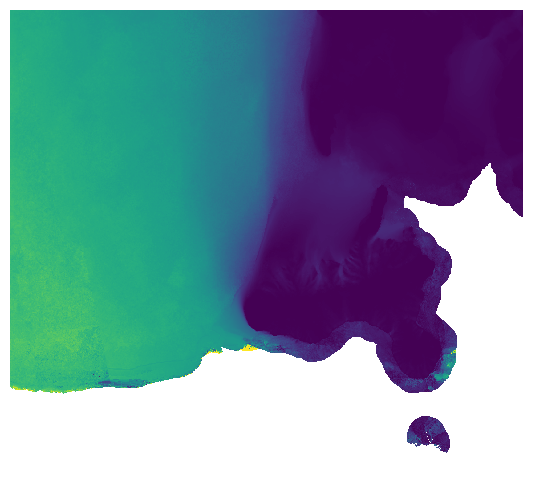

In [18]:
modis_ross = torch.load("/Users/kim.bente/DATA/MODIS/MODIS_regional/moa125_2014_hp1_v01_ross_island_with_grid_no_ocean.pt", weights_only = False)

fig, ax = plt.subplots(figsize = (8, 6))

# 1) MODIS as background (draw first)
ax.pcolormesh(
    modis_ross[0],
    modis_ross[1], 
    modis_ross[3],
    cmap = "gray",
    # softer greys
    vmin = -30_000, 
    vmax = 30_000,
    # as less saturated background
    alpha = 0.4,
    zorder = 0,
)

# 2) ice vel on top (draw second)
pcm = ax.pcolormesh(
    ice_vel_ITS_LIVE_ross_island.x,
    ice_vel_ITS_LIVE_ross_island.y,
    # Note: v is already computed
    ice_vel_ITS_LIVE_ross_island.v,
    cmap = "viridis",
    # Fix these limits for consistency
    vmin = 0,
    vmax = 1200,
    shading = "auto",
    # 1.0 for full opacity & consistency
    alpha = 1.0,
    zorder = 1,
)

ax.set_aspect("equal")
ax.set_axis_off()

# crop
ax.set_ylim(y_min, y_max)
ax.set_xlim(x_min, x_max)

fig.savefig("figures/ITS_LIVE_ice_vel_ross_island.png", dpi = 300, bbox_inches = "tight", pad_inches = 0)
plt.show()

# Interpolate the mask to subset region

data stays at og 450m grid. 

In [36]:
tighter_ice_shelf_mask = xr.load_dataarray("data/tighter_ice_shelf_mask.nc")

mask_for_ice_vel = tighter_ice_shelf_mask.interp(
    x = ice_vel_ross.x, 
    y = ice_vel_ross.y, 
    method = "nearest"
)

ice_vel_ross_on_target = ice_vel_ross.V.where(mask_for_ice_vel == 3)
ice_vel_ross_ds_on_target = ice_vel_ross.where(mask_for_ice_vel == 3)

# Load MODIS background

# Visualise

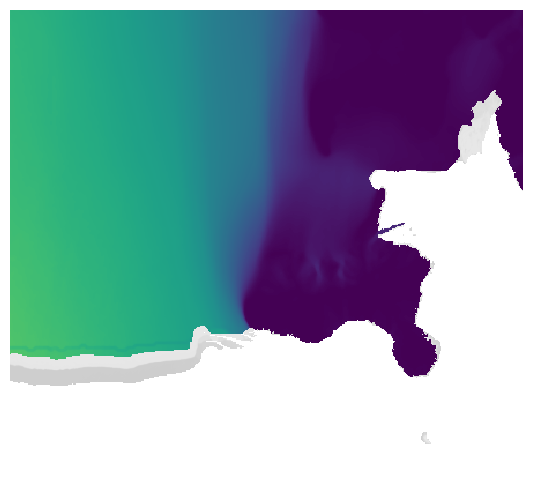

: 

In [ ]:
fig, ax = plt.subplots(figsize = (8, 6))

# 1) MODIS as background (draw first)
ax.pcolormesh(
    modis_ross[0],
    modis_ross[1], 
    modis_ross[2],
    cmap = "gray",
    # softer greys
    vmin = -30_000, 
    vmax = 30_000,
    # as less saturated background
    alpha = 0.4,
    zorder = 0,
)

# 2) ice vel on top (draw second)
pcm = ax.pcolormesh(
    ice_vel_ross_island.x,
    ice_vel_ross_island.y,
    ice_vel_ross_island.V,
    cmap = "viridis",
    # Fix these limits for consistency
    vmin = 0,
    vmax = 1200,
    shading = "auto",
    # 1.0 for full opacity & consistency
    alpha = 1.0,
    zorder = 1,
)

ax.set_aspect("equal")
ax.set_axis_off()

# crop
ax.set_ylim(y_min, y_max)
ax.set_xlim(x_min, x_max)

fig.savefig("figures/ice_vel_ross_island.png", dpi = 300, bbox_inches = "tight", pad_inches = 0)
plt.show()

# cmap

In [8]:
cmap = "viridis"
dpi = 300

# 1 x N gradient
grad = np.linspace(0, 1, 2048)[None, :]

fig = plt.figure(figsize = (6, 0.6), dpi = dpi)
ax = fig.add_axes([0, 0, 1, 1]) 
ax.imshow(grad, aspect = "auto", cmap = cmap)
ax.set_axis_off()

fig.savefig("figures/cmap/viridis_bar.png", dpi = dpi, transparent = True, bbox_inches = "tight", pad_inches = 0)
plt.close(fig)